001: yo diseño las relaciones entre posición y sonido.
002: la red recibe sonidos y aprende sola esas relaciones.
Luego comprime los sonidos en un espacio latente.
El teclado permite explorar ese espacio y escuchar sus variaciones.

Celda 1 — Instalar librerías

En Colab:

In [ ]:
!pip install tensorflow librosa

Celda 2 — Importar



In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models

from IPython.display import Audio

Celda 3 — Crear una pequeña colección de sonidos

Aquí genero mi propio "dataset":

Ahora tengo dos controles:

X  → movimiento horizontal
Y  → movimiento vertical

y cada posición produce un sonido.

¿Por qué este ejercicio importa a futuro?

la idea central:

TTT2:

gesto
 ↓
zona textil
 ↓
sonido asociado

001:

posición
 ↓
espacio latente
 ↓
sonido continuo

El siguiente paso será:

002 — Crear un espacio latente aprendido con un Autoencoder

La máquina empieza a encontrar relaciones.

Después:

003 — VAE + generación sonora

004 — SOM organizando el espacio

005 — reemplazar teclado por sensores textiles MPR121

es decir: # 001: X e Y funcionan como un espacio para explorar sonidos.
# Cada posición produce una variación sonora.
# En TTT2, el gesto activa una zona y un sonido asociado.
# En 001, el movimiento recorre un espacio sonoro continuo.
# Después la máquina aprenderá ese espacio con Autoencoder → VAE → SOM → MPR121.

Aquí tengo ya muchos sonidos diferentes.

In [ ]:

# ==========================================================
# CELDA — Crear dataset de sonidos sintéticos
# ==========================================================

import numpy as np


# ----------------------------------------------------------
# 1. PARÁMETROS DEL SONIDO
# ----------------------------------------------------------

sr = 22050
# sr = sample rate:
# cantidad de muestras del sonido por segundo.

duration = 1
# Duración de cada sonido: 1 segundo.


# ----------------------------------------------------------
# 2. EJE TEMPORAL
# ----------------------------------------------------------

t = np.linspace(
    0,
    duration,
    sr
)
# Crea los puntos de tiempo desde 0 hasta 1 segundo.
# Genera 22.050 muestras para cada sonido.


# ----------------------------------------------------------
# 3. FUNCIÓN DE SÍNTESIS
# ----------------------------------------------------------

def crear_sonido(freq, armonico):

    # freq = frecuencia fundamental.
    # armonico = múltiplo de la frecuencia fundamental
    # que modifica el timbre.

    # Frecuencia fundamental:
    # crea una onda sinusoidal, es decir, un tono puro.

    sonido = np.sin(
        2 * np.pi * freq * t
    )


    # Armónico:
    # agrega una segunda frecuencia relacionada
    # con la fundamental, con una intensidad del 30%.

    sonido += 0.3 * np.sin(
        2 * np.pi * freq * armonico * t
    )


    return sonido


# ----------------------------------------------------------
# 4. CREAR DATASET
# ----------------------------------------------------------

sonidos = []
# Lista vacía donde guardaremos todos los sonidos.


for f in range(100, 1000, 50):
    # Frecuencias desde 100 hasta 950 Hz,
    # aumentando de 50 en 50.

    for h in range(1, 6):
        # Para cada frecuencia probamos
        # 5 relaciones armónicas: 1, 2, 3, 4 y 5.

        s = crear_sonido(f, h)
        # Genera un sonido con esa frecuencia y armónico.

        sonidos.append(s)
        # Agrega el sonido a la lista.


# ----------------------------------------------------------
# 5. CONVERTIR A ARRAY
# ----------------------------------------------------------

sonidos = np.array(sonidos)
# Convierte la lista en un array de NumPy.


# ----------------------------------------------------------
# 6. COMPROBAR EL DATASET
# ----------------------------------------------------------

sonidos.shape
# Muestra cómo está organizada la información.
# Resultado esperado:
# (90, 22050)
#
# 90 sonidos × 22.050 muestras por sonido.



(90, 22050)

Celda 4 — Normalizar

In [ ]:
# ==========================================================
# CELDA — Normalizar sonidos
# ==========================================================

sonidos = sonidos / np.max(
    np.abs(sonidos)
)
# Normaliza todos los sonidos para que su amplitud
# quede dentro de un rango controlado (-1 a 1).

Celda 5 — Crear Autoencoder

La red tiene:

SONIDO
  |
Encoder
  |
LATENTE
  |
Decoder
  |
SONIDO RECONSTRUIDO

In [ ]:
# ==========================================================
# CELDA — Crear Autoencoder
# ==========================================================

from tensorflow.keras import Model, Input, layers


# ----------------------------------------------------------
# 1. DIMENSIÓN DE ENTRADA
# ----------------------------------------------------------

input_dim = sonidos.shape[1]
# Cantidad de muestras que tiene cada sonido.


# ----------------------------------------------------------
# 2. ENTRADA
# ----------------------------------------------------------

entrada = Input(
    shape=(input_dim,)
)
# Recibe un sonido completo como vector.


# ----------------------------------------------------------
# 3. ENCODER — COMPRIMIR EL SONIDO
# ----------------------------------------------------------

x = layers.Dense(
    128,
    activation="relu"
)(entrada)
# Reduce la información del sonido a 128 valores.


latente = layers.Dense(
    2,
    activation="linear",
    name="espacio_latente"
)(x)
# Comprime aún más hasta 2 valores: Z1 y Z2.
# Estos dos valores forman nuestro espacio latente.


# ----------------------------------------------------------
# 4. DECODER — RECONSTRUIR EL SONIDO
# ----------------------------------------------------------

x = layers.Dense(
    128,
    activation="relu"
)(latente)
# Expande nuevamente la información desde el espacio latente.


salida = layers.Dense(
    input_dim,
    activation="tanh"
)(x)
# Reconstruye el sonido original.


# ----------------------------------------------------------
# 5. MODELO COMPLETO
# ----------------------------------------------------------

modelo = Model(
    entrada,
    salida
)
# Une Encoder + espacio latente + Decoder.


# ----------------------------------------------------------
# 6. ENTRENAMIENTO
# ----------------------------------------------------------

modelo.compile(
    optimizer="adam",
    loss="mse"
)
# Adam ajusta la red.
# MSE mide cuánto se diferencia el sonido reconstruido
# del sonido original.


# ----------------------------------------------------------
# 7. VER LA ARQUITECTURA
# ----------------------------------------------------------

modelo.summary()
# Muestra las capas y parámetros del Autoencoder.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 22050)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,822,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ espacio_latente (Dense)         │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 22050)          │     2,844,450 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,667,620 (21.62 MB)

 Trainable params: 5,667,620 (21.62 MB)

 Non-trainable params: 0 (0.00 B)

Dense(2) crea el espacio latente de 2 dimensiones:
la red aprende a organizar los sonidos en un mapa que podemos explorar.

Celda 6 — Entrenar

In [ ]:
# ==========================================================
# CELDA — Entrenar Autoencoder
# ==========================================================

historia = modelo.fit(
    sonidos,
    sonidos,
    epochs=50,
    batch_size=16
)
# La red aprende a reconstruir los sonidos que recibe.
# epochs = cantidad de veces que recorre el dataset.
# batch_size = cantidad de sonidos procesados en cada grupo.

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - loss: 0.3592
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - loss: 0.3281
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.3011
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - loss: 0.2896
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 0.2723
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - loss: 0.2642
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - loss: 0.2592
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.2579
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - loss: 0.2542
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - loss: 0.2521
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 0.2506
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - loss: 0.2483
Epoch 13/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 0.2529
Epoch 14/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - loss: 0.2532
Epoch 15/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 0.2445
Epoch 16/50
6/6 ━━━━━━━━━━━━━━

Ahora la máquina intenta reconstruir los sonidos.

Celda 7 — Ver el mapa aprendido

Extraer el encoder:

In [ ]:
# ==========================================================
# CELDA — Probar reconstrucción
# ==========================================================

reconstruido = modelo(
    sonidos[:1]
)

# Toma el primer sonido y lo pasa por:
# Encoder → espacio latente → Decoder.
# El resultado es el sonido reconstruido.

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


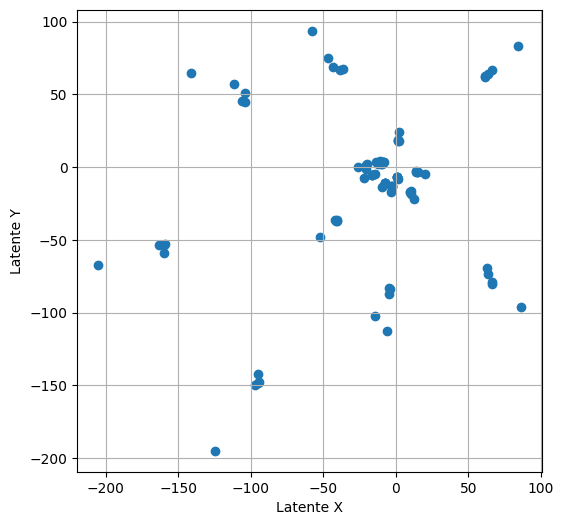

In [ ]:
# ==========================================================
# CELDA — Visualizar el espacio latente
# ==========================================================

# ----------------------------------------------------------
# 1. CREAR EL ENCODER
# ----------------------------------------------------------

encoder = models.Model(
    inputs=modelo.input,
    outputs=modelo.get_layer(
        "espacio_latente"
    ).output
)

# Creamos un modelo que usa solamente la parte Encoder.
# Así podemos obtener las coordenadas latentes de cada sonido.


# ----------------------------------------------------------
# 2. OBTENER LAS COORDENADAS LATENTES
# ----------------------------------------------------------

z = encoder.predict(
    sonidos
)

# Cada sonido se convierte en dos valores:
# Z1 y Z2.
#
# Ejemplo:
# sonido → [Z1, Z2]


# ----------------------------------------------------------
# 3. DIBUJAR EL ESPACIO LATENTE
# ----------------------------------------------------------

plt.figure(
    figsize=(6,6)
)

plt.scatter(
    z[:,0],
    z[:,1]
)

# Cada punto representa un sonido.
# Su posición indica dónde la red lo ubicó
# dentro del espacio latente.


# ----------------------------------------------------------
# 4. NOMBRAR LOS EJES
# ----------------------------------------------------------

plt.xlabel(
    "Latente X"
)

plt.ylabel(
    "Latente Y"
)


# ----------------------------------------------------------
# 5. MOSTRAR CUADRÍCULA
# ----------------------------------------------------------

plt.grid()


# ----------------------------------------------------------
# 6. MOSTRAR MAPA
# ----------------------------------------------------------

plt.show()

Esta celda extrae solamente el Decoder del Autoencoder, para poder darle directamente coordenadas (Z1, Z2) y generar un sonido.

In [ ]:
# ==========================================================
# CELDA — Extraer el Decoder
# ==========================================================

from tensorflow.keras import Model


# ----------------------------------------------------------
# 1. ENTRADA DEL DECODER
# ----------------------------------------------------------

decoder_input = modelo.get_layer(
    "dense_1"
).input

# El Decoder comienza en el espacio latente:
# Z1 y Z2.


# ----------------------------------------------------------
# 2. SALIDA DEL DECODER
# ----------------------------------------------------------

decoder_output = modelo.output

# Es el sonido reconstruido que produce el Decoder.


# ----------------------------------------------------------
# 3. CREAR EL DECODER
# ----------------------------------------------------------

decoder = Model(
    inputs=decoder_input,
    outputs=decoder_output
)

# Ahora tenemos un Decoder independiente:
#
# Z1, Z2 → Decoder → sonido


# ----------------------------------------------------------
# 4. VER EL MODELO
# ----------------------------------------------------------

decoder.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ keras_tensor_2CLONE             │ (None, 2)              │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 22050)          │     2,844,450 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,844,834 (10.85 MB)

 Trainable params: 2,844,834 (10.85 MB)

 Non-trainable params: 0 (0.00 B)

confirmar que está separado el decoder correctamente.

Ahora la arquitectura real quedó así:

                 AUTOENCODER

Audio (22050 muestras)
          |
          ↓
     Encoder
          |
          ↓
   espacio_latente
       (z1,z2)
          |
          ↓
      Decoder
          |
          ↓
Audio reconstruido
(22050 muestras)

Este decoder dice:

Input:  (None, 2)

Eso significa:

acepta un punto del espacio latente:

[z1, z2]

y lo transforma en:

22050 valores

que son una onda sonora de 1 segundo.

Ahora se hace la siguiente celda:

:Celda 9 — elegir una posición nueva en el espacio latente y dejar que el Decoder genere el sonido.

In [ ]:
# ==========================================================
# CELDA — Generar sonido desde el espacio latente
# ==========================================================

# ----------------------------------------------------------
# 1. ELEGIR UNA POSICIÓN LATENTE
# ----------------------------------------------------------

z_nuevo = np.array([
    [0.2, -0.1]
])

# Elegimos una nueva posición:
# Z1 = 0.2
# Z2 = -0.1


# ----------------------------------------------------------
# 2. GENERAR EL SONIDO
# ----------------------------------------------------------

sonido_nuevo = decoder.predict(
    z_nuevo
)

# El Decoder transforma Z1 y Z2
# en un nuevo sonido.


# ----------------------------------------------------------
# 3. ESCUCHAR EL RESULTADO
# ----------------------------------------------------------

Audio(
    sonido_nuevo[0],
    rate=sr
)

# Escuchamos el sonido generado
# desde esa posición del espacio latente.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


Ahora tengo:

punto latente (z1,z2)
        ↓
     decoder
        ↓
      audio

Pero todavía estoy eligiendo manualmente el punto:

z_nuevo = np.array([[0.2, -0.1]])

El siguiente paso es reemplazar esa coordenada fija por una interacción humana.


Celda 10 — convertir el espacio latente en un control interactivo

In [ ]:
# ==========================================================
# CELDA — Explorar el espacio latente
# ==========================================================

from ipywidgets import interact
from IPython.display import display, Audio


# ----------------------------------------------------------
# 1. CREAR CONTROLES
# ----------------------------------------------------------

@interact(
    z1=(-3.0, 3.0, 0.1),
    z2=(-3.0, 3.0, 0.1)
)

# Crear dos controles:
# Z1 = posición horizontal
# Z2 = posición vertical
#
# Podemos movernos entre -3 y 3.


# ----------------------------------------------------------
# 2. FUNCIÓN DE EXPLORACIÓN
# ----------------------------------------------------------

def explorar_latente(
    z1=0.0,
    z2=0.0
):

    # z1 y z2 indican una posición
    # dentro del espacio latente.


    # ------------------------------------------------------
    # 3. CREAR COORDENADA
    # ------------------------------------------------------

    z = np.array([
        [z1, z2]
    ])

    # Convertir la posición en un array
    # que puede recibir el Decoder.


    # ------------------------------------------------------
    # 4. GENERAR SONIDO
    # ------------------------------------------------------

    sonido = decoder.predict(z)

    # El Decoder transforma la posición latente
    # en un sonido.


    # ------------------------------------------------------
    # 5. ESCUCHAR
    # ------------------------------------------------------

    display(
        Audio(
            sonido[0],
            rate=sr
        )
    )

    # Reproduce el sonido generado.

interactive(children=(FloatSlider(value=0.0, description='z1', max=3.0, min=-3.0), FloatSlider(value=0.0, desc…

002 — Autoencoder
sonidos
 ↓
Autoencoder
 ↓
espacio latente aprendido
 ↓
decoder
 ↓
sonido reconstruido